# Quantifying Psychological Momentum and State Transitions in Speedcubing
**Abhishek Deepak Nair**

This notebook answers three questions using my own 3x3 solve log:

1. **Momentum** – does the last solve push the next one into a "Flow" or "Tilt" state?
2. **Tilt** – when things go badly, do I quit, or keep going (grind)?
3. **Warm-up** – are solves slower at the start of a session, or after a long pause?

**How we decide if a pattern is real: the shuffle test.**
We compare the real data with shuffled copies of it. Each solve is shuffled only among the solves of its own
session, so every session keeps the same times in a new order. We recompute everything on each shuffled copy.
The shuffled copies show the range of results that **chance alone** produces. If the real result falls
**outside** the range that holds the middle 95% of the shuffled results, chance rarely produces it, so the
pattern is likely real. If it falls **inside**, chance could easily explain it.
Every shuffle test is run with 5 different random seeds (1,000 shuffles each) to check the answer is the same.

**How we show uncertainty: 95% confidence interval** = average ± 1.96 × standard error (Central Limit Theorem).

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, rand_score

DATA_FILE = "3x3_3.csv"

SESSION_GAP = 300      # seconds: a gap longer than 5 minutes starts a new session
COLD_SOLVES = 5        # the first 5 solves of each session are Cold (they have no "Ao5 of the previous 5")
LEVEL_WINDOW = 51      # the level = median of the 51 solves around each solve
N_SHUFFLES = 1000      # shuffles per random seed
SEEDS = [0, 1, 2, 3, 4]   # every shuffle test is repeated with 5 seeds

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ecebe7"
plt.rcParams["axes.axisbelow"] = True     # draw grid lines behind the bars
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)


def save_figure(fig, name):
    fig.savefig("figs/" + name + ".png", dpi=200, bbox_inches="tight")
    fig.savefig("figs/" + name + ".pdf", bbox_inches="tight")


import os
os.makedirs("figs", exist_ok=True)

### Small helper functions used throughout

In [2]:
def pearson(x, y):
    """Pearson correlation coefficient r: how strongly x and y move together in a straight line (-1 to +1)."""
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    keep = ~np.isnan(x) & ~np.isnan(y)
    return np.corrcoef(x[keep], y[keep])[0, 1]


def mean_and_ci(values):
    """Average and its 95% confidence interval (Central Limit Theorem)."""
    values = np.array(values, dtype=float)
    values = values[~np.isnan(values)]
    mean = values.mean()
    standard_error = values.std(ddof=1) / np.sqrt(len(values))
    return mean, mean - 1.96 * standard_error, mean + 1.96 * standard_error


def difference_and_ci(group_a, group_b):
    """Difference between two averages (a - b) and its 95% confidence interval."""
    a = np.array(group_a, dtype=float)
    b = np.array(group_b, dtype=float)
    diff = a.mean() - b.mean()
    standard_error = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return diff, diff - 1.96 * standard_error, diff + 1.96 * standard_error


def shuffled_range(shuffled_values):
    """The range that holds the middle 95% of the shuffled results."""
    return np.percentile(shuffled_values, 2.5), np.percentile(shuffled_values, 97.5)


summary_rows = []      # every comparison is collected here and shown as a table at the end


def compare_with_chance(name, real_value, shuffled_values):
    """Is the real value inside or outside the range of the shuffled results? Also checked for each seed separately."""
    shuffled_values = np.array(shuffled_values)
    low, high = shuffled_range(shuffled_values)
    inside = low <= real_value <= high
    answers = []
    for i in range(len(SEEDS)):
        one_seed = shuffled_values[i * N_SHUFFLES:(i + 1) * N_SHUFFLES]
        seed_low, seed_high = shuffled_range(one_seed)
        answers.append(seed_low <= real_value <= seed_high)
    same_for_every_seed = all(answers) or not any(answers)
    verdict = "INSIDE (chance could explain it)" if inside else "OUTSIDE (chance rarely produces this)"
    print(f"{name}: real {real_value:+.3f}, shuffled range {low:+.3f} to {high:+.3f} -> {verdict}; "
          f"same answer for every seed: {same_for_every_seed}")
    summary_rows.append((name, round(real_value, 3), round(low, 3), round(high, 3), "inside" if inside else "OUTSIDE",
                         same_for_every_seed))

## 1. Load and clean the data
* **DNF** ("did not finish") attempts are removed.
* A **+2** penalty adds 2 seconds to the time.
* The **gap** is the time between two timestamps. Timestamps are written when a solve ends (checked below).
* **Rest** = gap − solve time = scrambling + inspection + any pause before the solve.

In [3]:
raw = pd.read_csv(DATA_FILE)
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.sort_values("date").reset_index(drop=True)
print(len(raw), "attempts from", raw["date"].min().date(), "to", raw["date"].max().date())
print(raw["penalty"].value_counts())

raw["gap"] = raw["date"].diff().dt.total_seconds()

# Is the timestamp written at the end of a solve? Then the gap should follow the CURRENT solve time.
short_gaps = raw[(raw["gap"] < 120) & (raw["penalty"] == "none")]
previous_time = raw["time"].shift(1)
print("r(gap, current solve)  =", round(pearson(short_gaps["gap"], short_gaps["time"]), 2))
print("r(gap, previous solve) =", round(pearson(short_gaps["gap"], previous_time[short_gaps.index]), 2))

raw["rest"] = raw["gap"] - raw["time"]

# Sessions: a new session starts after a gap longer than 5 minutes
session_numbers = []
session = 0
for gap in raw["gap"]:
    if np.isnan(gap) or gap > SESSION_GAP:
        session = session + 1
    session_numbers.append(session)
raw["session"] = session_numbers
raw.loc[raw["gap"] > SESSION_GAP, "rest"] = np.nan    # a break between sessions is not a "rest"

# Remove DNFs, add +2 penalties
data = raw[raw["penalty"] != "DNF"].copy()
data = data[data["time"] > 0].reset_index(drop=True)
data["t"] = data["time"]
data.loc[data["penalty"] == "+2", "t"] = data["time"] + 2

# Position of each solve inside its session (0 = first solve), session length, and whether it is the last solve
data["position"] = data.groupby("session").cumcount()
data["session_length"] = data.groupby("session")["t"].transform("size")
data["is_last"] = data["position"] == data["session_length"] - 1

# The level: median of the 51 solves around each solve. Deviation = how much slower than the level.
data["level"] = data["t"].rolling(LEVEL_WINDOW, center=True, min_periods=17).median()
data["deviation"] = data["t"] - data["level"]

N = len(data)
times = data["t"].values
sessions = data["session"].values
positions = data["position"].values
rests = data["rest"].values
levels = data["level"].values

# the row numbers of the solves in each session (looked up once, used everywhere)
SESSION_ROWS = []
for s in np.unique(sessions):
    SESSION_ROWS.append(np.where(sessions == s)[0])

print(N, "solves in", data["session"].nunique(), "sessions")
print("average", round(times.mean(), 2), "s, median", round(np.median(times), 2), "s, standard deviation", round(times.std(ddof=1), 2), "s")
print("median rest:", round(np.nanmedian(rests), 1), "s")

1053 attempts from 2026-09-20 to 2026-11-09
penalty
none    1044
+2         5
DNF        4
Name: count, dtype: int64
r(gap, current solve)  = 0.33
r(gap, previous solve) = 0.15
1049 solves in 51 sessions
average 16.57 s, median 16.1 s, standard deviation 3.15 s
median rest: 22.4 s


### Core functions: Ao5, shuffling, states and transition matrix

In [4]:
def compute_ao5(solve_times):
    """Ao5 = average of the current and previous 4 solves in the same session, best and worst dropped."""
    ao5 = np.full(N, np.nan)
    for i in range(N):
        if positions[i] >= 4:                       # needs 5 solves in this session
            last_five = sorted(solve_times[i - 4:i + 1])
            ao5[i] = np.mean(last_five[1:4])        # drop the best and the worst
    return ao5


def previous_ao5(solve_times):
    """Ao5 of the 5 solves BEFORE each solve, in the same session (first available at the 6th solve)."""
    ao5 = compute_ao5(solve_times)
    previous = np.full(N, np.nan)
    previous[1:] = ao5[:-1]
    previous[~same_session_as_previous] = np.nan
    return previous


def shuffle_within_sessions(solve_times, rng):
    """Shuffle the times inside each session (each session keeps its own times, in a new order)."""
    shuffled = solve_times.copy()
    for idx in SESSION_ROWS:
        shuffled[idx] = rng.permutation(solve_times[idx])
    return shuffled


# pairs of consecutive solves that are in the same session (used for correlations)
same_session_as_previous = np.zeros(N, dtype=bool)
same_session_as_previous[1:] = sessions[1:] == sessions[:-1]


def consecutive_r(values):
    """Pearson r between each solve and the next one in the same session."""
    previous = values[:-1][same_session_as_previous[1:]]
    current = values[1:][same_session_as_previous[1:]]
    return pearson(previous, current)

---
# Question 1 — Momentum and state transitions
## Q1.1 Choosing the features: why not Ao5 directly?
The proposal planned to use solve time, **Ao5** and rest. But neighbouring Ao5 values share 4 of their 5 solves,
so they are almost the same number, and any state built on Ao5 repeats "by construction".
Instead we compare each solve **with** the Ao5 of the previous 5 solves: **time − previous Ao5**
("was this solve better or worse than my last few?"). It also partly accounts for the day's level,
because each solve is compared with recent solves from the same day.

In [5]:
data["ao5"] = compute_ao5(times)
data["prev_ao5"] = previous_ao5(times)
data["vs_prev_ao5"] = data["t"] - data["prev_ao5"]

ao5_values = data["ao5"].values
new_values = data["vs_prev_ao5"].values
pairs_ao5 = same_session_as_previous[1:] & ~np.isnan(ao5_values[1:]) & ~np.isnan(ao5_values[:-1])
pairs_new = same_session_as_previous[1:] & ~np.isnan(new_values[1:]) & ~np.isnan(new_values[:-1])
print("Neighbouring Ao5 values:               r =", round(pearson(ao5_values[:-1][pairs_ao5], ao5_values[1:][pairs_ao5]), 2))
print("Neighbouring (time - previous Ao5):    r =", round(pearson(new_values[:-1][pairs_new], new_values[1:][pairs_new]), 2))

# For comparison: K-Means on the proposal's original features (time, Ao5, rest)
has_old = ~np.isnan(ao5_values) & ~np.isnan(rests)
old_labels = np.full(N, -1)
old_labels[has_old] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(
    StandardScaler().fit_transform(data.loc[has_old, ["t", "ao5", "rest"]].values))
both_old = (old_labels[1:] >= 0) & (old_labels[:-1] >= 0) & same_session_as_previous[1:]
old_repeat = np.mean(old_labels[1:][both_old] == old_labels[:-1][both_old])
old_share = np.bincount(old_labels[has_old]) / has_old.sum()
print(f"With Ao5 as a feature, the state repeats {old_repeat:.2f} of the time; "
      f"independent states would repeat {np.sum(old_share ** 2):.2f}")

Neighbouring Ao5 values:               r = 0.88
Neighbouring (time - previous Ao5):    r = -0.02
With Ao5 as a feature, the state repeats 0.65 of the time; independent states would repeat 0.48


## Q1.2 K-Means states
Features: **solve time, time − previous Ao5, and rest**. They are **standardised** (put on the same scale) and
grouped with K-Means. **k = 3 is chosen by design**: the proposal studies three states.
K-Means uses k-means++ starting points and 20 starts.

In [6]:
has_features = ~np.isnan(data["vs_prev_ao5"].values) & ~np.isnan(rests)
features = data.loc[has_features, ["t", "vs_prev_ao5", "rest"]].values

scaler = StandardScaler()
scaled = scaler.fit_transform(features)
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=20, random_state=0)
clusters = kmeans.fit_predict(scaled)

# Name the clusters: the one with the longest rests is "Long rest"; of the other two, faster = Flow, slower = Tilt
cluster_mean_time = [features[clusters == c, 0].mean() for c in range(3)]
cluster_mean_rest = [features[clusters == c, 2].mean() for c in range(3)]
long_rest_cluster = int(np.argmax(cluster_mean_rest))
other_two = [c for c in range(3) if c != long_rest_cluster]
if cluster_mean_time[other_two[0]] < cluster_mean_time[other_two[1]]:
    flow_cluster, tilt_cluster = other_two[0], other_two[1]
else:
    flow_cluster, tilt_cluster = other_two[1], other_two[0]
cluster_name = {flow_cluster: "Flow", tilt_cluster: "Tilt", long_rest_cluster: "Long rest"}

data["kmeans_group"] = None
data.loc[has_features, "kmeans_group"] = [cluster_name[c] for c in clusters]

# The long-rest group is folded into Cold: a rest at least as long as the shortest rest in that group counts as Cold
LONG_REST = int(np.floor(features[clusters == long_rest_cluster, 2].min()))
print("Long-rest group starts at a rest of", LONG_REST, "s")

print(len(features), "solves have all three features")
print("silhouette score:", round(silhouette_score(scaled, clusters), 3))

# Repeat the whole fit with 20 different random seeds: do we get the same groups? (Rand index, 1 = identical)
rand_values = []
for seed in range(1, 21):
    other_fit = KMeans(n_clusters=3, init="k-means++", n_init=20, random_state=seed).fit_predict(scaled)
    rand_values.append(rand_score(clusters, other_fit))
print("Rand index over 20 repeated fits: average", round(np.mean(rand_values), 3), "minimum", round(np.min(rand_values), 3))

group_table = data[has_features].groupby("kmeans_group")[["t", "vs_prev_ao5", "rest", "deviation"]].mean().round(2)
group_table["solves"] = data[has_features]["kmeans_group"].value_counts()
group_table["shortest rest"] = data[has_features].groupby("kmeans_group")["rest"].min().round(1)
group_table

Long-rest group starts at a rest of 79 s
841 solves have all three features
silhouette score: 0.466
Rand index over 20 repeated fits: average 1.0 minimum 1.0


,t,vs_prev_ao5,rest,deviation,solves,shortest rest
kmeans_group,,,,,,
Flow,14.74,-1.43,24.01,-1.19,541,12.4
Long rest,16.50,0.43,132.73,0.59,30,79.5
Tilt,19.64,3.41,26.67,3.25,270,14.7


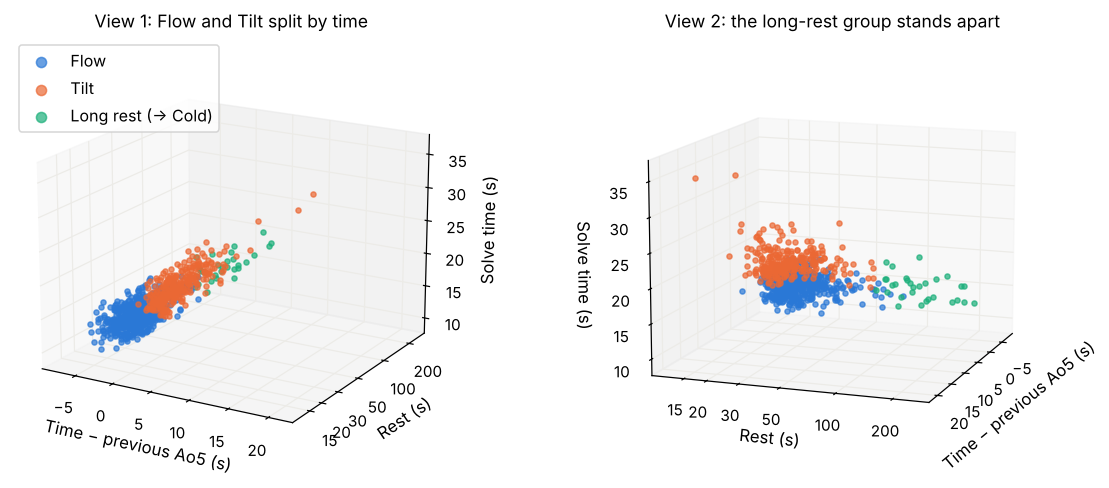

In [7]:
group_colour = {"Flow": BLUE, "Tilt": ORANGE, "Long rest": GREEN}
fig = plt.figure(figsize=(11, 5.2))
views = [(18, -60, "View 1: Flow and Tilt split by time"), (12, 20, "View 2: the long-rest group stands apart")]
for k in range(2):
    elevation, angle, title = views[k]
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    for group in ["Flow", "Tilt", "Long rest"]:
        part = data[data["kmeans_group"] == group]
        label = group + " (→ Cold)" if group == "Long rest" else group
        ax.scatter(part["vs_prev_ao5"], np.log10(part["rest"]), part["t"], s=11, color=group_colour[group], alpha=0.7,
                   depthshade=False, label=label)
    ax.set_xlabel("Time − previous Ao5 (s)", fontsize=11)
    ax.set_ylabel("Rest (s)", fontsize=11)
    ax.set_zlabel("Solve time (s)", fontsize=11)
    rest_ticks = [15, 20, 30, 50, 100, 200]
    ax.set_yticks(np.log10(rest_ticks))
    ax.set_yticklabels(rest_ticks)
    ax.view_init(elev=elevation, azim=angle)
    ax.set_title(title, fontsize=11.5)
    if k == 0:
        ax.legend(loc="upper left", fontsize=10.5, markerscale=2)
fig.subplots_adjust(wspace=0.05, left=0.0, right=0.97)
save_figure(fig, "q1_fig1_states_3d")
plt.show()

## Q1.3 The Cold state: the first 5 solves of a session
**Why 5:** "time − previous Ao5" needs 5 earlier solves, so the first 5 solves of a session don't have it
and K-Means cannot place them.

**Does the data agree?** The warm-up curve compares each position with the session's own warm speed
(the average of its solves from the 11th on), using sessions with at least 15 solves.

In [8]:
def warmup_curve(solve_times):
    """For positions 1..15: how much slower than the session's warm speed (sessions with >= 15 solves)."""
    rows = []
    for idx in SESSION_ROWS:
        if len(idx) < 15:
            continue
        warm_speed = solve_times[idx[10:]].mean()          # solves 11 onwards
        for p in range(15):
            rows.append((p + 1, solve_times[idx[p]] - warm_speed))
    return pd.DataFrame(rows, columns=["position", "slower_than_warm"])


def cold_penalty_per_session(solve_times, cold_count):
    """For each session with >= 10 solves: average of the first `cold_count` solves minus average of the rest."""
    penalties = []
    for idx in SESSION_ROWS:
        if len(idx) < 10:
            continue
        penalties.append(solve_times[idx[:cold_count]].mean() - solve_times[idx[cold_count:]].mean())
    return np.array(penalties)


def window_chosen_by_eye(solve_times):
    """Count how many opening positions sit above the warm speed before the first one drops below it."""
    curve = warmup_curve(solve_times).groupby("position")["slower_than_warm"].mean()
    count = 0
    while count < 10 and curve[count + 1] > 0:
        count = count + 1
    return count


curve = warmup_curve(times).groupby("position")["slower_than_warm"].agg(["mean", "std", "count"])
curve["ci"] = 1.96 * curve["std"] / np.sqrt(curve["count"])

real_penalties = cold_penalty_per_session(times, COLD_SOLVES)
cold_mean, cold_low, cold_high = mean_and_ci(real_penalties)
print("Window chosen by eye from the curve:", window_chosen_by_eye(times))
print(f"Cold penalty: {cold_mean:+.2f} s per solve, 95% CI [{cold_low:.2f}, {cold_high:.2f}], "
      f"{len(real_penalties)} sessions, slower in {100 * np.mean(real_penalties > 0):.0f}% of them")
curve.round(2).T

Window chosen by eye from the curve: 5
Cold penalty: +0.60 s per solve, 95% CI [0.02, 1.18], 30 sessions, slower in 67% of them


position,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
mean,0.52,0.51,0.30,0.79,0.18,-0.72,-0.17,0.10,-0.36,-0.61,-0.13,-0.01,0.94,-0.64,-0.27
std,3.27,3.75,2.48,2.60,3.79,2.60,2.43,1.92,2.16,2.14,2.83,3.25,2.57,1.83,2.29
count,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00
ci,1.21,1.39,0.92,0.96,1.40,0.96,0.90,0.71,0.80,0.79,1.05,1.20,0.95,0.68,0.85


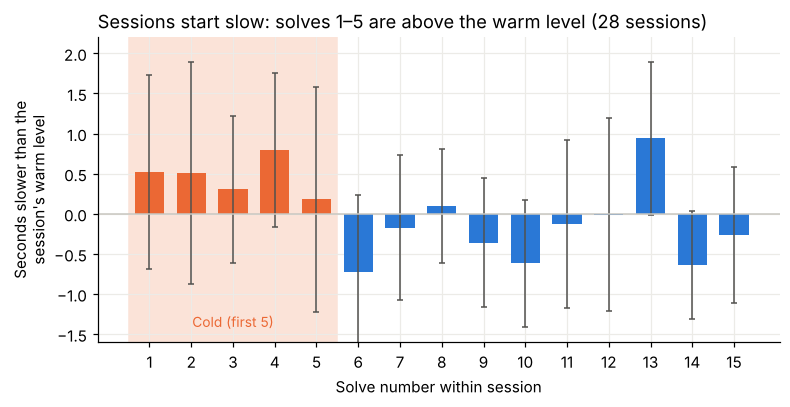

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = curve.index.values
bar_colours = [ORANGE if p <= COLD_SOLVES else BLUE for p in x]
ax.axvspan(0.5, COLD_SOLVES + 0.5, color="#fbe3d8", zorder=0)
ax.text(3, -1.45, "Cold (first 5)", color=ORANGE, fontsize=9, ha="center", va="bottom")
ax.bar(x, curve["mean"], color=bar_colours, width=0.7)
ax.errorbar(x, curve["mean"], yerr=curve["ci"], fmt="none", ecolor="#52514e", lw=1, capsize=2)
ax.axhline(0, color="#c9c7c1", lw=1)
ax.set_ylim(-1.6, 2.2)
ax.set_xticks(x)
ax.set_xlabel("Solve number within session")
ax.set_ylabel("Seconds slower than the\nsession's warm level")
ax.set_title("Sessions start slow: solves 1–5 are above the warm level (28 sessions)", loc="left")
save_figure(fig, "q1_fig2_cold_state")
plt.show()

**Held-out check.** For each session, choose the window from the *other* sessions (same "by eye" rule),
then measure the penalty on the left-out session only. This avoids testing a choice on the data that suggested it.

In [10]:
held_out_windows = []
held_out_penalties = []
for idx in SESSION_ROWS:
    if len(idx) < 10:
        continue
    # choose the window without this session: give its solves NaN so they are left out of the curve
    times_without = times.copy()
    times_without[idx] = np.nan
    curve_without = warmup_curve(times_without).dropna().groupby("position")["slower_than_warm"].mean()
    window = 0
    while window < 10 and curve_without[window + 1] > 0:
        window = window + 1
    held_out_windows.append(window)
    held_out_penalties.append(times[idx[:window]].mean() - times[idx[window:]].mean() if window > 0 else 0.0)

held_mean, held_low, held_high = mean_and_ci(held_out_penalties)
print("Window chosen without each session:", pd.Series(held_out_windows).value_counts().to_dict())
print(f"Held-out cold penalty: {held_mean:+.2f} s per solve, 95% CI [{held_low:.2f}, {held_high:.2f}]; "
      f"slower in {100 * np.mean(np.array(held_out_penalties) > 0):.0f}% of sessions")

Window chosen without each session: {5: 27, 4: 2, 1: 1}
Held-out cold penalty: +0.27 s per solve, 95% CI [-0.26, 0.80]; slower in 60% of sessions


## Q1.4 States for every solve, and the transition matrix
* **Cold** = one of the first 5 solves of a session, or a solve after a long rest
  (the K-Means long-rest group is folded into Cold; the cut-off is where that group starts).
* Every other solve gets its K-Means state, **Flow** or **Tilt**.

Transitions are counted between every pair of consecutive solves in the whole log, **including across breaks**.
So Tilt → Cold means "I stopped or paused right after a Tilt solve".

In [11]:
STATES = ["Cold", "Flow", "Tilt"]
flow_centre = kmeans.cluster_centers_[flow_cluster]
tilt_centre = kmeans.cluster_centers_[tilt_cluster]


def label_states(solve_times):
    """Give every solve a state (Cold, Flow or Tilt) using the K-Means model fitted on the real data."""
    vs_prev = solve_times - previous_ao5(solve_times)
    states = np.array(["Cold"] * N, dtype=object)
    is_cold = (positions < COLD_SOLVES) | (np.nan_to_num(rests) >= LONG_REST)
    warm = ~is_cold
    scaled_warm = scaler.transform(np.column_stack([solve_times[warm], vs_prev[warm], rests[warm]]))
    predicted = kmeans.predict(scaled_warm)
    warm_states = []
    for row, c in zip(scaled_warm, predicted):
        if c == flow_cluster:
            warm_states.append("Flow")
        elif c == tilt_cluster:
            warm_states.append("Tilt")
        else:
            # rare: lands in the long-rest group without a long rest -> use the nearer of Flow and Tilt
            if np.sum((row - flow_centre) ** 2) < np.sum((row - tilt_centre) ** 2):
                warm_states.append("Flow")
            else:
                warm_states.append("Tilt")
    states[warm] = warm_states
    return states


STATE_NUMBER = {"Cold": 0, "Flow": 1, "Tilt": 2}


def transition_matrix(states):
    """Count transitions between consecutive solves, then turn each row into probabilities."""
    counts = np.zeros((3, 3))
    for i in range(N - 1):
        counts[STATE_NUMBER[states[i]], STATE_NUMBER[states[i + 1]]] += 1
    probabilities = counts / counts.sum(axis=1, keepdims=True)
    return (pd.DataFrame(counts.astype(int), index=STATES, columns=STATES),
            pd.DataFrame(probabilities, index=STATES, columns=STATES))


def matrix_distance(matrix_a, matrix_b):
    """Sum of the absolute differences of the 9 cells."""
    return np.abs(matrix_a.values - matrix_b.values).sum()


data["state"] = label_states(times)
real_counts, real_matrix = transition_matrix(data["state"].values)
print("Counts:")
print(real_counts)
print("\nProbabilities:")
print(real_matrix.round(3))

Counts:
      Cold  Flow  Tilt
Cold   178    39    21
Flow    34   335   171
Tilt    26   166    78

Probabilities:
       Cold   Flow   Tilt
Cold  0.748  0.164  0.088
Flow  0.063  0.620  0.317
Tilt  0.096  0.615  0.289


## Q1.5 The main shuffle loop
For every shuffle we shuffle the times inside each session, then recompute **everything** and store it:
the transition matrix, the cold penalty, the window "chosen by eye", the correlation between consecutive solves,
and whether sessions end after Tilt or Flow.
The same loop is then repeated with a **completely random shuffle** (all solves in one bag).

In [12]:
def quit_difference(states):
    """% of Tilt solves that end the session minus % of Flow solves that end it."""
    is_last = data["is_last"].values
    return is_last[states == "Tilt"].mean() - is_last[states == "Flow"].mean()


shuffled = {"matrix": [], "cold_penalty": [], "cold_by_eye": [], "window_by_eye": [], "lag1_deviation": [],
            "lag1_raw": [], "quit_difference": []}
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    for i in range(N_SHUFFLES):
        shuffled_times = shuffle_within_sessions(times, rng)
        states = label_states(shuffled_times)
        shuffled["matrix"].append(transition_matrix(states)[1])
        shuffled["cold_penalty"].append(cold_penalty_per_session(shuffled_times, COLD_SOLVES).mean())
        window = window_chosen_by_eye(shuffled_times)
        shuffled["window_by_eye"].append(window)
        shuffled["cold_by_eye"].append(cold_penalty_per_session(shuffled_times, window).mean() if window > 0 else 0.0)
        shuffled["lag1_deviation"].append(consecutive_r(shuffled_times - levels))
        shuffled["lag1_raw"].append(consecutive_r(shuffled_times))
        shuffled["quit_difference"].append(quit_difference(states))

random_matrices = []
random_lag1_raw = []
for seed in SEEDS:
    rng = np.random.default_rng(100 + seed)
    for i in range(N_SHUFFLES):
        random_times = rng.permutation(times)          # completely random: ignores sessions
        random_matrices.append(transition_matrix(label_states(random_times))[1])
        random_lag1_raw.append(consecutive_r(random_times))
print("done:", len(shuffled["matrix"]), "within-session shuffles and", len(random_matrices), "completely random shuffles")

done: 5000 within-session shuffles and 5000 completely random shuffles


## Q1.6 Results: real matrix vs the two kinds of shuffle
For each of the 9 cells we check whether the real value is inside the range of the shuffled copies.
For the matrix as a whole, we measure its distance from the average shuffled matrix
(sum of the 9 differences) and compare that with the distances of the shuffled copies themselves.

In [13]:
def compare_with_shuffles(shuffled_matrices, name):
    average = sum(shuffled_matrices) / len(shuffled_matrices)
    stacked = np.array([m.values for m in shuffled_matrices])
    low, high = np.percentile(stacked, 2.5, axis=0), np.percentile(stacked, 97.5, axis=0)
    inside = ((real_matrix.values >= low) & (real_matrix.values <= high)).sum()
    real_distance = matrix_distance(real_matrix, average)
    shuffled_distances = [matrix_distance(m, average) for m in shuffled_matrices]
    print(f"{name}: {inside} of 9 cells inside the shuffled 95% range")
    for i, from_state in enumerate(real_matrix.index):
        for j, to_state in enumerate(real_matrix.columns):
            if not (low[i, j] <= real_matrix.values[i, j] <= high[i, j]):
                print(f"   outside: {from_state} -> {to_state}: real {real_matrix.values[i, j]:.3f}, "
                      f"shuffled range {low[i, j]:.3f} to {high[i, j]:.3f}")
    compare_with_chance(name + ": whole-matrix distance", real_distance, shuffled_distances)
    print(average.round(3), "\n")
    return average


within_average = compare_with_shuffles(shuffled["matrix"], "Within-session shuffle")
random_average = compare_with_shuffles(random_matrices, "Completely random shuffle")

r_raw = consecutive_r(times)
compare_with_chance("Consecutive raw times r vs completely random shuffle", r_raw, random_lag1_raw)
compare_with_chance("Consecutive raw times r vs within-session shuffle", r_raw, shuffled["lag1_raw"])

# what X -> Cold means: the session ended, or a long pause inside the session
next_state = np.append(data["state"].values[1:], "end")
into_cold = data[(data["state"] != "Cold") & (next_state == "Cold")]
print("\nTransitions into Cold:")
print(pd.crosstab(into_cold["state"], np.where(into_cold["is_last"], "stopped (new session)", "long pause")))

Within-session shuffle: 9 of 9 cells inside the shuffled 95% range
Within-session shuffle: whole-matrix distance: real +0.066, shuffled range +0.034 to +0.198 -> INSIDE (chance could explain it); same answer for every seed: True
       Cold   Flow   Tilt
Cold  0.748  0.163  0.090
Flow  0.073  0.610  0.317
Tilt  0.077  0.613  0.310 

Completely random shuffle: 8 of 9 cells inside the shuffled 95% range
   outside: Flow -> Flow: real 0.620, shuffled range 0.550 to 0.612
Completely random shuffle: whole-matrix distance: real +0.127, shuffled range +0.036 to +0.197 -> INSIDE (chance could explain it); same answer for every seed: True
       Cold   Flow   Tilt
Cold  0.748  0.161  0.091
Flow  0.074  0.581  0.345
Tilt  0.074  0.616  0.309 

Consecutive raw times r vs completely random shuffle: real +0.120, shuffled range -0.063 to +0.062 -> OUTSIDE (chance rarely produces this); same answer for every seed: True
Consecutive raw times r vs within-session shuffle: real +0.120, shuffled range +0.

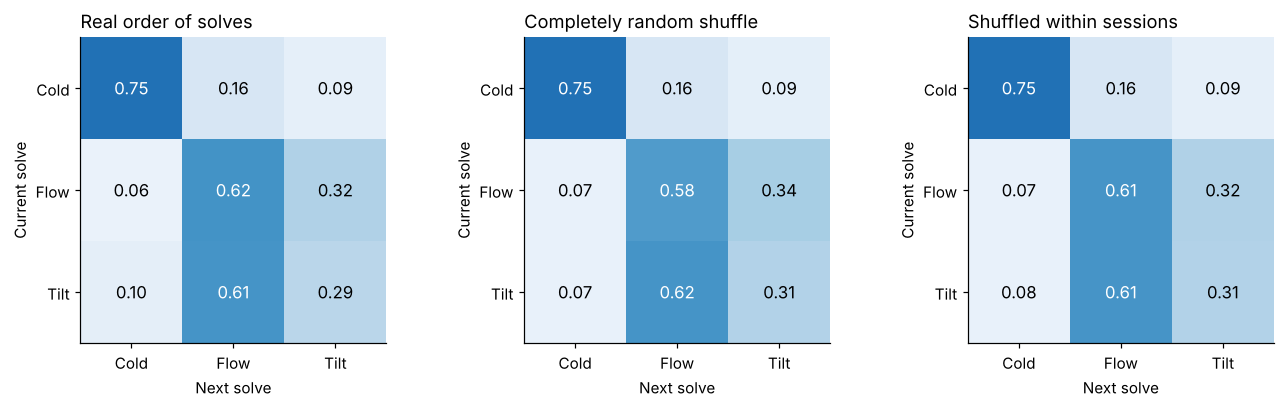

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [(real_matrix, "Real order of solves"), (random_average, "Completely random shuffle"),
          (within_average, "Shuffled within sessions")]
for ax, (matrix, title) in zip(axes, panels):
    ax.imshow(matrix.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3))
    ax.set_xticklabels(STATES)
    ax.set_yticks(range(3))
    ax.set_yticklabels(STATES)
    ax.set_xlabel("Next solve")
    ax.set_ylabel("Current solve")
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            value = matrix.values[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=11, color="white" if value > 0.5 else "black")
    ax.set_title(title, loc="left")
fig.subplots_adjust(wspace=0.45)
save_figure(fig, "q1_fig3_markov")
plt.show()

### The Cold penalty against the shuffles
* **Fixed window of 5:** do shuffled sessions show a penalty this large?
* **Window chosen by eye on every shuffle:** the fair comparison if 5 had been chosen by looking at the curve.

In [15]:
compare_with_chance("Cold penalty (window fixed at 5)", cold_mean, shuffled["cold_penalty"])
compare_with_chance("Cold penalty (window chosen by eye on every shuffle)", cold_mean, shuffled["cold_by_eye"])
windows = np.array(shuffled["window_by_eye"])
print(f"Shuffled sessions 'start slow' in {100 * np.mean(windows >= 1):.0f}% of shuffles, "
      f"with 3+ slow solves in {100 * np.mean(windows >= 3):.0f}%")

Cold penalty (window fixed at 5): real +0.600, shuffled range -0.505 to +0.514 -> OUTSIDE (chance rarely produces this); same answer for every seed: True
Cold penalty (window chosen by eye on every shuffle): real +0.600, shuffled range +0.000 to +0.963 -> INSIDE (chance could explain it); same answer for every seed: True
Shuffled sessions 'start slow' in 47% of shuffles, with 3+ slow solves in 13%


## Q1.7 The level: why past solves still predict
**Level** = median of the 51 solves around each solve (about 3 sessions / 2 days). **Deviation** = time − level.

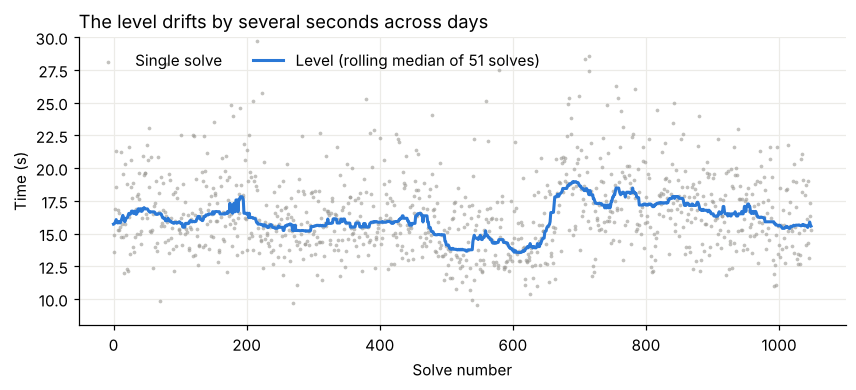

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.scatter(range(N), times, s=6, color=GREY, alpha=0.6, linewidths=0, label="Single solve")
ax.plot(range(N), levels, color=BLUE, lw=2, label="Level (rolling median of 51 solves)")
ax.set_xlabel("Solve number")
ax.set_ylabel("Time (s)")
ax.set_ylim(8, 30)
ax.legend(loc="upper left", ncol=2, frameon=False)
ax.set_title("The level drifts by several seconds across days", loc="left")
save_figure(fig, "q1_fig4_level_timeline")
plt.show()

Raw times: r = 0.120.  Level removed: r = -0.021, 95% CI [-0.083, 0.041], 998 pairs
Consecutive solves, level removed (r): real -0.021, shuffled range -0.056 to +0.067 -> INSIDE (chance could explain it); same answer for every seed: True
The last solve explains at most 0.7% of the next solve's variation; after a solve 2.9 s slow, the next is at most 0.24 s slower


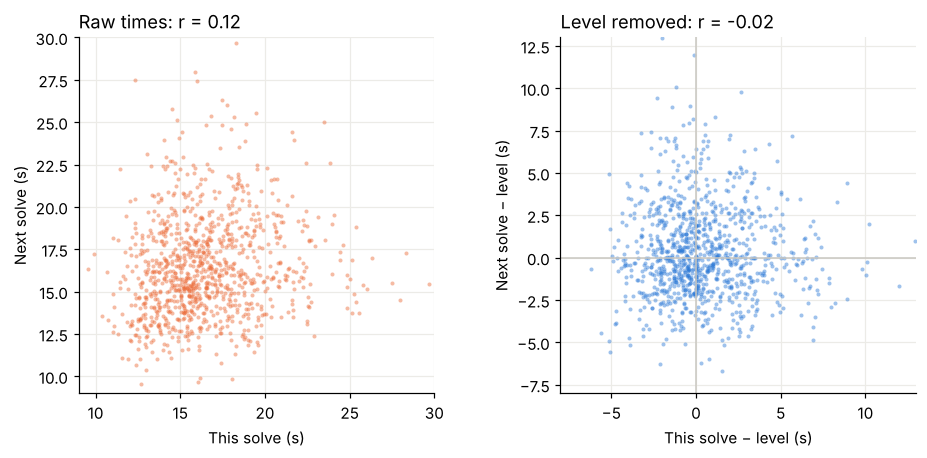

In [17]:
deviations = data["deviation"].values
r_deviation = consecutive_r(deviations)
n_pairs = int(same_session_as_previous.sum())
r_low, r_high = r_deviation - 1.96 / np.sqrt(n_pairs), r_deviation + 1.96 / np.sqrt(n_pairs)
largest_r = max(abs(r_low), abs(r_high))
print(f"Raw times: r = {r_raw:.3f}.  Level removed: r = {r_deviation:.3f}, 95% CI [{r_low:.3f}, {r_high:.3f}], {n_pairs} pairs")
compare_with_chance("Consecutive solves, level removed (r)", r_deviation, shuffled["lag1_deviation"])
print(f"The last solve explains at most {100 * largest_r ** 2:.1f}% of the next solve's variation; "
      f"after a solve {np.nanstd(deviations, ddof=1):.1f} s slow, the next is at most {largest_r * np.nanstd(deviations, ddof=1):.2f} s slower")

previous_t = times[:-1][same_session_as_previous[1:]]
current_t = times[1:][same_session_as_previous[1:]]
previous_d = deviations[:-1][same_session_as_previous[1:]]
current_d = deviations[1:][same_session_as_previous[1:]]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].scatter(previous_t, current_t, s=7, color=ORANGE, alpha=0.45, linewidths=0)
axes[0].set_xlim(9, 30)
axes[0].set_ylim(9, 30)
axes[0].set_aspect("equal")
axes[0].set_xlabel("This solve (s)")
axes[0].set_ylabel("Next solve (s)")
axes[0].set_title(f"Raw times: r = {r_raw:.2f}", loc="left")
axes[1].scatter(previous_d, current_d, s=7, color=BLUE, alpha=0.45, linewidths=0)
axes[1].axhline(0, color="#c9c7c1", lw=1)
axes[1].axvline(0, color="#c9c7c1", lw=1)
axes[1].set_xlim(-8, 13)
axes[1].set_ylim(-8, 13)
axes[1].set_aspect("equal")
axes[1].set_xlabel("This solve − level (s)")
axes[1].set_ylabel("Next solve − level (s)")
axes[1].set_title(f"Level removed: r = {r_deviation:.2f}", loc="left")
fig.subplots_adjust(wspace=0.3)
save_figure(fig, "q1_fig5_pairs")
plt.show()

### Predicting the next solve from the past only
Each solve from #101 on is predicted by the average of the previous k solves (no future solves are used).
**R² (coefficient of determination)** = 1 − (average squared error) / (variance of the times):
the share of the ups and downs the prediction captures. 0 = no better than always guessing the average.

average of last   1 solves: R² = -0.700
average of last   2 solves: R² = -0.235
average of last   3 solves: R² = -0.112
average of last   5 solves: R² = -0.033
average of last  10 solves: R² = +0.049
average of last  15 solves: R² = +0.072
average of last  20 solves: R² = +0.088
average of last  25 solves: R² = +0.086
average of last  30 solves: R² = +0.089
average of last  50 solves: R² = +0.071
average of last 100 solves: R² = +0.040
best: 30 solves


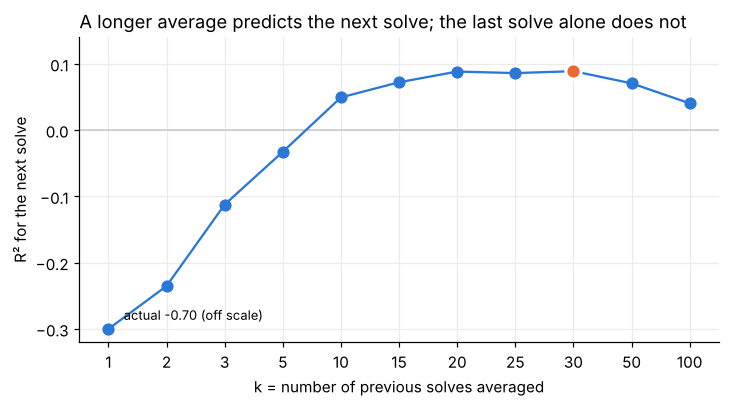

In [18]:
K_VALUES = [1, 2, 3, 5, 10, 15, 20, 25, 30, 50, 100]
targets = times[100:]
r2_values = []
for k in K_VALUES:
    predictions = []
    for i in range(100, N):
        predictions.append(times[i - k:i].mean())
    squared_error = np.mean((targets - np.array(predictions)) ** 2)
    r2_values.append(1 - squared_error / np.var(targets))
best_k = K_VALUES[int(np.argmax(r2_values))]
for k, r2 in zip(K_VALUES, r2_values):
    print(f"average of last {k:3d} solves: R² = {r2:+.3f}")
print("best:", best_k, "solves")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axhline(0, color="#c9c7c1", lw=1)
shown = [max(r, -0.3) for r in r2_values]
ax.plot(range(len(K_VALUES)), shown, "o-", color=BLUE, ms=7)
ax.annotate(f"actual {r2_values[0]:.2f} (off scale)", (0, -0.3), xytext=(10, 6), textcoords="offset points", fontsize=8.5)
ax.plot(K_VALUES.index(best_k), max(r2_values), "o", color=ORANGE, ms=10, mec="white", mew=2)
ax.set_xticks(range(len(K_VALUES)))
ax.set_xticklabels(K_VALUES)
ax.set_ylim(-0.32, 0.14)
ax.set_xlabel("k = number of previous solves averaged")
ax.set_ylabel("R² for the next solve")
ax.set_title("A longer average predicts the next solve; the last solve alone does not", loc="left")
save_figure(fig, "q1_fig6_past_only_prediction")
plt.show()

---
# Question 2 — When things go badly: quit or grind?
* **Quit:** the session ends (a break of 5 min or more) right after a Tilt solve.
* **Grind:** keep going through a bad session.

In [19]:
flow_or_tilt = data[data["state"].isin(["Flow", "Tilt"])].copy()
tilt = flow_or_tilt[flow_or_tilt["state"] == "Tilt"]
flow = flow_or_tilt[flow_or_tilt["state"] == "Flow"]
quit_tilt = tilt["is_last"].mean()
quit_flow = flow["is_last"].mean()
quit_diff, quit_low, quit_high = difference_and_ci(tilt["is_last"].astype(float), flow["is_last"].astype(float))
print(f"Session ends after {100 * quit_tilt:.1f}% of Tilt solves ({len(tilt)}) and {100 * quit_flow:.1f}% of Flow solves ({len(flow)})")
print(f"Difference {100 * quit_diff:+.1f} points, 95% CI [{100 * quit_low:.1f}, {100 * quit_high:.1f}]; "
      f"{int(flow_or_tilt['is_last'].sum())} session ends among these solves")
compare_with_chance("Quit: % ending after Tilt minus after Flow", quit_tilt - quit_flow, shuffled["quit_difference"])

# Grind: for each session, the share of its Flow/Tilt solves that are Tilt, against how long the session lasted
session_rows = []
for s in np.unique(sessions):
    part = flow_or_tilt[flow_or_tilt["session"] == s]
    if len(part) < 5:
        continue
    whole = data[data["session"] == s]
    session_rows.append((s, (part["state"] == "Tilt").mean(), len(whole), whole["t"].median()))
per_session = pd.DataFrame(session_rows, columns=["session", "tilt_share", "length", "median_time"])
r_grind = pearson(per_session["tilt_share"], per_session["length"])

# shuffle test: give the session lengths to sessions at random
shuffled_r = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    for i in range(N_SHUFFLES):
        shuffled_r.append(pearson(per_session["tilt_share"], rng.permutation(per_session["length"].values)))

middle_share = per_session["tilt_share"].median()
more_tilt = per_session[per_session["tilt_share"] > middle_share]       # the half of sessions with more Tilt
less_tilt = per_session[per_session["tilt_share"] <= middle_share]
print(f"\nGrind: r(Tilt share, session length) = {r_grind:.2f}, {len(per_session)} sessions")
compare_with_chance("Grind: r(Tilt share, session length)", r_grind, shuffled_r)
print(f"Tilt share in the middle session: {100 * middle_share:.0f}%. Median length: sessions with more Tilt "
      f"{more_tilt['length'].median()} solves ({len(more_tilt)} sessions), sessions with less Tilt "
      f"{less_tilt['length'].median()} solves ({len(less_tilt)} sessions)")

# Pacing (the proposal's wording): does the rest before the next solve get shorter after a Tilt solve?
next_rest = data.groupby("session")["rest"].shift(-1)
flow_or_tilt["rest_change"] = next_rest[flow_or_tilt.index] - flow_or_tilt["rest"]
with_change = flow_or_tilt.dropna(subset=["rest_change"])
pace_diff, pace_low, pace_high = difference_and_ci(with_change[with_change["state"] == "Tilt"]["rest_change"],
                                                   with_change[with_change["state"] == "Flow"]["rest_change"])
print(f"\nPacing: change in rest after Tilt minus after Flow = {pace_diff:+.1f} s, 95% CI [{pace_low:.1f}, {pace_high:.1f}]")

Session ends after 5.2% of Tilt solves (270) and 3.5% of Flow solves (540)
Difference +1.7 points, 95% CI [-1.4, 4.7]; 33 session ends among these solves
Quit: % ending after Tilt minus after Flow: real +0.017, shuffled range -0.023 to +0.033 -> INSIDE (chance could explain it); same answer for every seed: True

Grind: r(Tilt share, session length) = 0.03, 30 sessions
Grind: r(Tilt share, session length): real +0.034, shuffled range -0.343 to +0.378 -> INSIDE (chance could explain it); same answer for every seed: True
Tilt share in the middle session: 30%. Median length: sessions with more Tilt 26.5 solves (14 sessions), sessions with less Tilt 30.0 solves (16 sessions)

Pacing: change in rest after Tilt minus after Flow = +2.2 s, 95% CI [-1.7, 6.1]


### What "Tilt" actually measures
Because each solve is compared with the Ao5 of the previous 5, Tilt solves are almost always slower than that
day's level. Raw time is still one of the features, so Tilt is also more common on slow days.

In [20]:
r_tilt_level = pearson(per_session["median_time"], per_session["tilt_share"])
slow_sessions = per_session[per_session["median_time"] > 17]
fast_sessions = per_session[per_session["median_time"] < 15]
not_at_level = flow_or_tilt[flow_or_tilt["deviation"] != 0]
tilt_faster = (not_at_level[not_at_level["state"] == "Tilt"]["deviation"] < 0).mean()
flow_slower = (not_at_level[not_at_level["state"] == "Flow"]["deviation"] > 0).mean()
print(f"r(session median time, Tilt share) = {r_tilt_level:.2f}; sessions slower than 17 s are "
      f"{100 * slow_sessions['tilt_share'].mean():.0f}% Tilt, faster than 15 s are {100 * fast_sessions['tilt_share'].mean():.0f}% Tilt")
print(f"{100 * tilt_faster:.0f}% of Tilt solves were faster than that day's level; {100 * flow_slower:.0f}% of Flow solves were slower")

# Side note, without K-Means: first 5 solves of a session vs my median over the previous 100 solves
side_rows = []
for s in np.unique(sessions):
    idx = np.where(sessions == s)[0]
    first = idx[0]
    if len(idx) < 5 or first < 30:
        continue
    usual = np.median(times[max(0, first - 100):first])
    side_rows.append((np.median(times[idx[:5]]) - usual, len(idx)))
side = pd.DataFrame(side_rows, columns=["start_vs_usual", "length"])
r_side = pearson(side["start_vs_usual"], side["length"])
shuffled_side = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    for i in range(N_SHUFFLES):
        shuffled_side.append(pearson(side["start_vs_usual"], rng.permutation(side["length"].values)))
print(f"Side note: r(bad start, session length) = {r_side:.2f}, {len(side)} sessions")
compare_with_chance("Side note: r(bad start, session length)", r_side, shuffled_side)

r(session median time, Tilt share) = 0.81; sessions slower than 17 s are 47% Tilt, faster than 15 s are 19% Tilt
1% of Tilt solves were faster than that day's level; 22% of Flow solves were slower
Side note: r(bad start, session length) = -0.17, 35 sessions
Side note: r(bad start, session length): real -0.170, shuffled range -0.307 to +0.375 -> INSIDE (chance could explain it); same answer for every seed: True


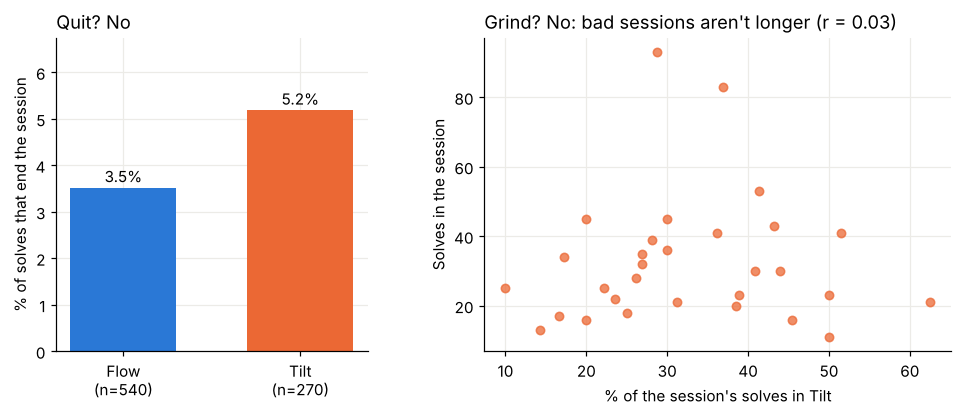

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), gridspec_kw={"width_ratios": [0.8, 1.2]})
values = [100 * quit_flow, 100 * quit_tilt]
axes[0].bar([0, 1], values, color=[BLUE, ORANGE], width=0.6)
for i in range(2):
    axes[0].text(i, values[i] + 0.12, f"{values[i]:.1f}%", ha="center")
axes[0].set_ylim(0, max(values) * 1.3)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels([f"Flow\n(n={len(flow)})", f"Tilt\n(n={len(tilt)})"])
axes[0].set_ylabel("% of solves that end the session")
axes[0].set_title("Quit? No", loc="left")
axes[1].scatter(100 * per_session["tilt_share"], per_session["length"], s=30, color=ORANGE, alpha=0.75)
axes[1].set_xlabel("% of the session's solves in Tilt")
axes[1].set_ylabel("Solves in the session")
axes[1].set_title(f"Grind? No: bad sessions aren't longer (r = {r_grind:.2f})", loc="left")
fig.subplots_adjust(wspace=0.3)
save_figure(fig, "q2_fig1_quit_grind")
plt.show()

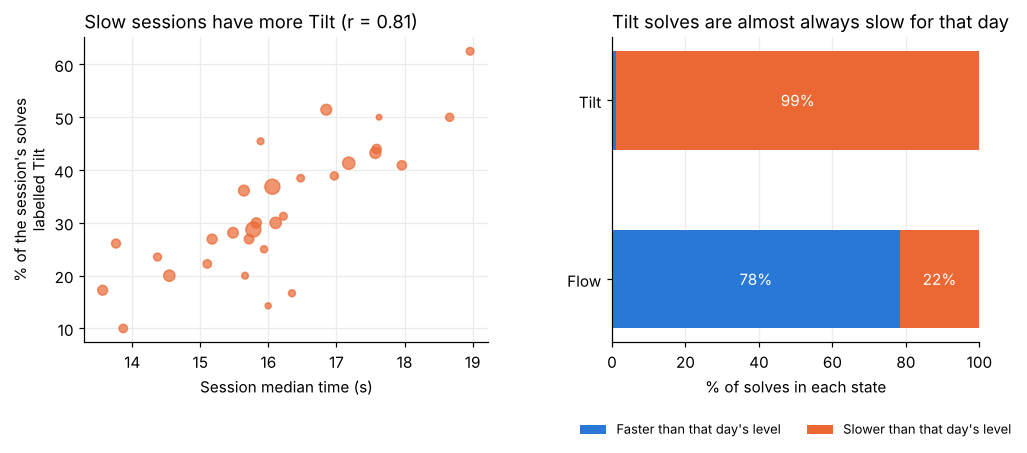

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].scatter(per_session["median_time"], 100 * per_session["tilt_share"],
                s=np.clip(per_session["length"], 10, 80) * 1.2, color=ORANGE, alpha=0.7)
axes[0].set_xlabel("Session median time (s)")
axes[0].set_ylabel("% of the session's solves\nlabelled Tilt")
axes[0].set_title(f"Slow sessions have more Tilt (r = {r_tilt_level:.2f})", loc="left")
faster = [100 * (not_at_level[not_at_level["state"] == g]["deviation"] < 0).mean() for g in ["Flow", "Tilt"]]
slower = [100 - f for f in faster]
axes[1].barh(["Flow", "Tilt"], faster, color=BLUE, label="Faster than that day's level", height=0.55)
axes[1].barh(["Flow", "Tilt"], slower, left=faster, color=ORANGE, label="Slower than that day's level", height=0.55)
for i in range(2):
    if faster[i] >= 5:    # skip labels too small to fit inside the bar
        axes[1].text(faster[i] / 2, i, f"{faster[i]:.0f}%", ha="center", va="center", color="white")
    axes[1].text(faster[i] + slower[i] / 2, i, f"{slower[i]:.0f}%", ha="center", va="center", color="white")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("% of solves in each state")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8.5, frameon=False)
axes[1].set_title("Tilt solves are almost always slow for that day", loc="left")
fig.subplots_adjust(wspace=0.32)
save_figure(fig, "q2_fig2_tilt_means_slow_session")
plt.show()

---
# Question 3 — Rest before a solve
**Assumption:** scrambling + inspection take about the same time every solve, so changes in the gap are changes in rest.
We use the solves after the first 5 of each session.

In [23]:
q3 = data[(data["position"] >= COLD_SOLVES) & data["rest"].notna() & data["deviation"].notna()]
r_rest = pearson(q3["rest"], q3["deviation"])
long_pause = q3[q3["rest"] > 20]
short_pause = q3[q3["rest"] <= 20]
step, step_low, step_high = difference_and_ci(long_pause["deviation"], short_pause["deviation"])

# shuffle test: shuffle the rests inside each session (the solve times stay where they are)
q3_rests = q3["rest"].values
q3_deviation = q3["deviation"].values
q3_sessions = q3["session"].values
shuffled_r_rest = []
shuffled_step = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    for i in range(N_SHUFFLES):
        shuffled_rests = q3_rests.copy()
        for s in np.unique(q3_sessions):
            idx = np.where(q3_sessions == s)[0]
            shuffled_rests[idx] = rng.permutation(q3_rests[idx])
        shuffled_r_rest.append(pearson(shuffled_rests, q3_deviation))
        shuffled_step.append(q3_deviation[shuffled_rests > 20].mean() - q3_deviation[shuffled_rests <= 20].mean())
print(f"{len(q3)} solves. r(rest, deviation) = {r_rest:.3f}")
compare_with_chance("Q3: r(rest, deviation)", r_rest, shuffled_r_rest)
print(f"Rest > 20 s vs <= 20 s: {step:+.2f} s, 95% CI [{step_low:.2f}, {step_high:.2f}] ({len(long_pause)} vs {len(short_pause)} solves)")
compare_with_chance("Q3: rest > 20 s minus rest <= 20 s", step, shuffled_step)
print("largest shuffled gap out of", len(shuffled_step), "shuffles:", round(max(shuffled_step), 2), "s")

bins = [0, 20, 25, 40, 120, 300]
rest_rows = []
for low, high in zip(bins[:-1], bins[1:]):
    part = q3[(q3["rest"] > low) & (q3["rest"] <= high)]["deviation"]
    mean, ci_low, ci_high = mean_and_ci(part)
    rest_rows.append((f"{low}-{high} s", mean, ci_low, ci_high, len(part)))
rest_table = pd.DataFrame(rest_rows, columns=["rest", "average", "ci_low", "ci_high", "solves"])
rest_table.round(2)

841 solves. r(rest, deviation) = 0.034
Q3: r(rest, deviation): real +0.034, shuffled range -0.055 to +0.080 -> INSIDE (chance could explain it); same answer for every seed: True
Rest > 20 s vs <= 20 s: +0.66 s, 95% CI [0.25, 1.07] (586 vs 255 solves)
Q3: rest > 20 s minus rest <= 20 s: real +0.659, shuffled range -0.460 to +0.310 -> OUTSIDE (chance rarely produces this); same answer for every seed: True
largest shuffled gap out of 5000 shuffles: 0.58 s


,rest,average,ci_low,ci_high,solves
0,0-20 s,-0.16,-0.50,0.17,255
1,20-25 s,0.38,0.06,0.69,291
2,25-40 s,0.64,0.22,1.05,219
3,40-120 s,0.57,-0.03,1.17,62
4,120-300 s,0.39,-0.68,1.47,14


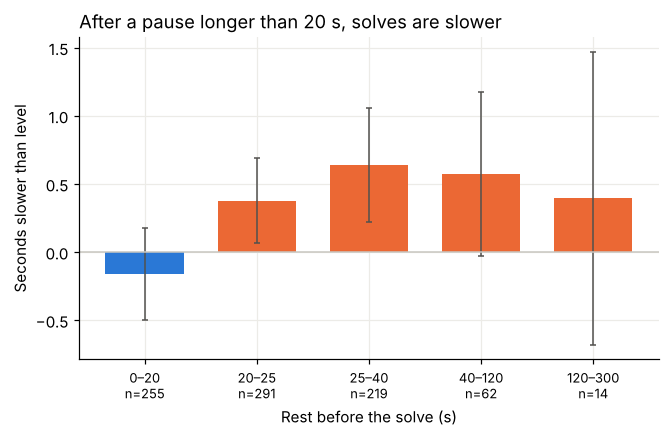

In [24]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
x = np.arange(len(rest_table))
ax.bar(x, rest_table["average"], color=[BLUE] + [ORANGE] * (len(x) - 1), width=0.7)
ax.errorbar(x, rest_table["average"], yerr=[rest_table["average"] - rest_table["ci_low"], rest_table["ci_high"] - rest_table["average"]],
            fmt="none", ecolor="#52514e", lw=1, capsize=2)
ax.axhline(0, color="#c9c7c1", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([f"{b[0]}–{b[1]}\nn={n}" for b, n in zip(zip(bins[:-1], bins[1:]), rest_table["solves"])], fontsize=8.5)
ax.set_xlabel("Rest before the solve (s)")
ax.set_ylabel("Seconds slower than level")
ax.set_title("After a pause longer than 20 s, solves are slower", loc="left")
save_figure(fig, "q3_fig1_rest")
plt.show()

### How the shuffle test works (example figure for the report)
Left: the rest gap. The real value is far outside everything 5,000 shuffles produced, so chance doesn't explain it.
Right: the rest correlation. The real value sits in the middle of the shuffled results, so chance explains it easily.

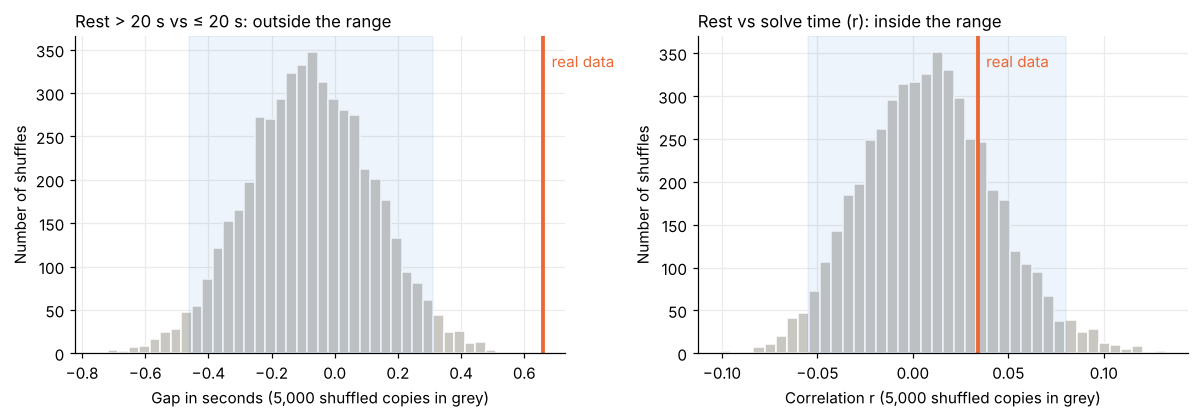

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
examples = [(shuffled_step, step, "Rest > 20 s vs ≤ 20 s: outside the range", "Gap in seconds"),
            (shuffled_r_rest, r_rest, "Rest vs solve time (r): inside the range", "Correlation r")]
for ax, (values, real, title, xlabel) in zip(axes, examples):
    low, high = shuffled_range(values)
    ax.hist(values, bins=40, color="#c9c7c1", edgecolor="white")
    ax.axvspan(low, high, color=BLUE, alpha=0.08)
    ax.axvline(real, color=ORANGE, lw=2.5)
    ax.text(real, ax.get_ylim()[1] * 0.95, "  real data", color=ORANGE, va="top")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel + " (5,000 shuffled copies in grey)")
    ax.set_ylabel("Number of shuffles")
fig.tight_layout()
save_figure(fig, "fig0_shuffle_test_example")
plt.show()

---
# Summary of every shuffle comparison
"inside" = chance could explain the real value; "OUTSIDE" = chance rarely produces it.
The last column checks that each of the 5 seeds gives the same answer.

In [26]:
summary = pd.DataFrame(summary_rows, columns=["comparison", "real value", "shuffled range from", "shuffled range to",
                                              "real value is", "same for every seed"])
summary

,comparison,real value,shuffled range from,shuffled range to,real value is,same for every seed
0,Within-session shuffle: whole-matrix distance,0.066,0.034,0.198,inside,True
1,Completely random shuffle: whole-matrix distance,0.127,0.036,0.197,inside,True
2,Consecutive raw times r vs completely random shuffle,0.120,-0.063,0.062,OUTSIDE,True
3,Consecutive raw times r vs within-session shuffle,0.120,0.078,0.183,inside,True
4,Cold penalty (window fixed at 5),0.600,-0.505,0.514,OUTSIDE,True
5,Cold penalty (window chosen by eye on every shuffle),0.600,0.000,0.963,inside,True
6,"Consecutive solves, level removed (r)",-0.021,-0.056,0.067,inside,True
7,Quit: % ending after Tilt minus after Flow,0.017,-0.023,0.033,inside,True
8,"Grind: r(Tilt share, session length)",0.034,-0.343,0.378,inside,True
9,"Side note: r(bad start, session length)",-0.170,-0.307,0.375,inside,True
